## 03. LINEAR REGRESSION

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("Food_Delivery_Times (1).csv")


In [3]:
df.head()

,s,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [4]:
df.shape

(1000, 9)

In [5]:
df.columns

Index(['s', 'Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day',
       'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs',
       'Delivery_Time_min'],
      dtype='object')

In [6]:
df.rename(columns={'s': 'Order_ID'}, inplace=True)

In [7]:
print(df.columns)

Index(['Order_ID', 'Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day',
       'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs',
       'Delivery_Time_min'],
      dtype='object')


In [8]:
df.isnull().sum()

Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64

In [9]:
df.describe()

,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.000000,1000.000000,1000.000000,970.000000,1000.000000
mean,500.500000,10.059970,16.982000,4.579381,56.732000
std,288.819436,5.696656,7.204553,2.914394,22.070915
min,1.000000,0.590000,5.000000,0.000000,8.000000
25%,250.750000,5.105000,11.000000,2.000000,41.000000
50%,500.500000,10.190000,17.000000,5.000000,55.500000
75%,750.250000,15.017500,23.000000,7.000000,71.000000
max,1000.000000,19.990000,29.000000,9.000000,153.000000


## HANDLING THE NULL VALUES

### Fill the missing values in the categorical columns by replacing them with the most frequent value in each column.

In [10]:
categorical_cols = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [11]:
df['Courier_Experience_yrs'] = df['Courier_Experience_yrs'].fillna(df['Courier_Experience_yrs'].median())

In [12]:
df.isnull().sum()

Order_ID                  0
Distance_km               0
Weather                   0
Traffic_Level             0
Time_of_Day               0
Vehicle_Type              0
Preparation_Time_min      0
Courier_Experience_yrs    0
Delivery_Time_min         0
dtype: int64

## Visualizing the Data
Visualize the relationships between all pairs of variables in the dataset to see patterns and correlations.

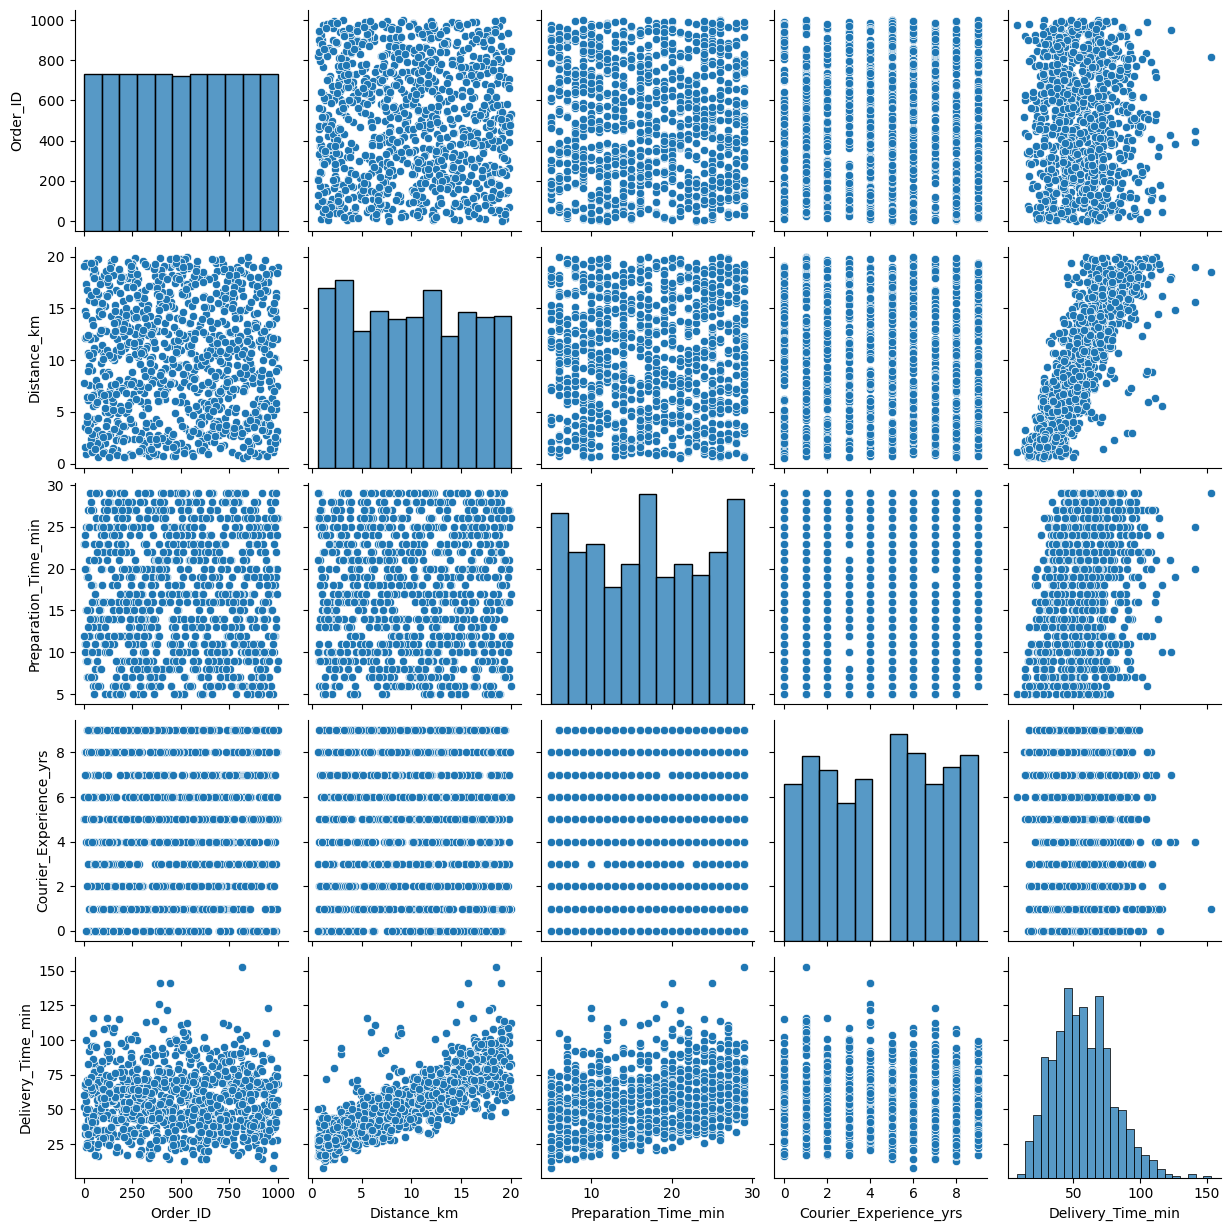

In [13]:
sns.pairplot(df)
plt.show()

### Mapping Values
Linear Regression works only on numeric data, so we need to convert categorical columns into numbers.

In [14]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df_copy = df.copy()

df['Weather'] = le.fit_transform(df['Weather'])
df['Traffic_Level'] = le.fit_transform(df['Traffic_Level'])
df['Time_of_Day'] = le.fit_transform(df['Time_of_Day'])
df['Vehicle_Type'] = le.fit_transform(df['Vehicle_Type'])

In [15]:
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,4,1,0,2,12,1.0,43
1,738,16.42,0,2,1,0,20,2.0,84
2,741,9.52,1,1,3,2,28,1.0,59
3,661,7.44,2,2,0,2,5,1.0,37
4,412,19.03,0,1,2,0,16,5.0,68


In [16]:
df_copy

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68
...,...,...,...,...,...,...,...,...,...
995,107,8.50,Clear,High,Evening,Car,13,3.0,54
996,271,16.28,Rainy,Low,Morning,Scooter,8,9.0,71
997,861,15.62,Snowy,High,Evening,Scooter,26,2.0,81
998,436,14.17,Clear,Low,Afternoon,Bike,8,0.0,55


In [17]:
cols = ['Weather','Traffic_Level','Time_of_Day','Vehicle_Type']

In [18]:
df_dummies = pd.get_dummies(df, columns= cols)

In [19]:
df_dummies = df_dummies.astype(int)

In [20]:
df_dummies.head()

,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min,Weather_0,Weather_1,Weather_2,Weather_3,Weather_4,Traffic_Level_0,Traffic_Level_1,Traffic_Level_2,Time_of_Day_0,Time_of_Day_1,Time_of_Day_2,Time_of_Day_3,Vehicle_Type_0,Vehicle_Type_1,Vehicle_Type_2
0,522,7,12,1,43,0,0,0,0,1,0,1,0,1,0,0,0,0,0,1
1,738,16,20,2,84,1,0,0,0,0,0,0,1,0,1,0,0,1,0,0
2,741,9,28,1,59,0,1,0,0,0,0,1,0,0,0,0,1,0,0,1
3,661,7,5,1,37,0,0,1,0,0,0,0,1,1,0,0,0,0,0,1
4,412,19,16,5,68,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0


In [21]:
df_dummies.shape

(1000, 20)

## **Defining Features and Target**

X (features) → known factors (distance, traffic, weather, etc.)

y (target) → what we want to predict (delivery time)


In [22]:
X = df_dummies.drop("Delivery_Time_min", axis=1)
y = df_dummies["Delivery_Time_min"]

In [23]:
x_encoded = df_dummies.drop("Delivery_Time_min", axis=1) 
y_encoded = df_dummies["Delivery_Time_min"]

## Splitting Data into Train and Test Sets**

How can we check how well our model performs on unseen data?
Why do we split the dataset into two parts:

Training set (80%) → used to train the model

Testing set (20%) → used to evaluate the modelbrary.


In [24]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [25]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x_encoded, y_encoded, test_size=0.2, random_state=42)


## Training the Linear Regression Model**


In [26]:
from sklearn.linear_model import LinearRegression,Ridge,Lasso
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [27]:
X_train, X_test, y_train, y_test = train_test_split(x_encoded, y_encoded, test_size=0.2, random_state=42)


In [28]:
from sklearn.linear_model import LinearRegression,Ridge,Lasso
model_encoded = LinearRegression()
model_encoded.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


## Making Predictions

Use the trained model to predict delivery times for the test data.

In [29]:
y_pred = model.predict(X_test)

## **Evaluating the Model**

Check how accurate your predictions are by calculating the average error, squared error, and R² score.


In [30]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

mean_absolute_error(y_test, y_pred)
mean_squared_error(y_test, y_pred)
r2_score(y_test, y_pred)


0.8184688733014349

### **Visualizing Predictions**


Create a scatter plot to compare actual vs predicted delivery times and visually check how well the model is performing.


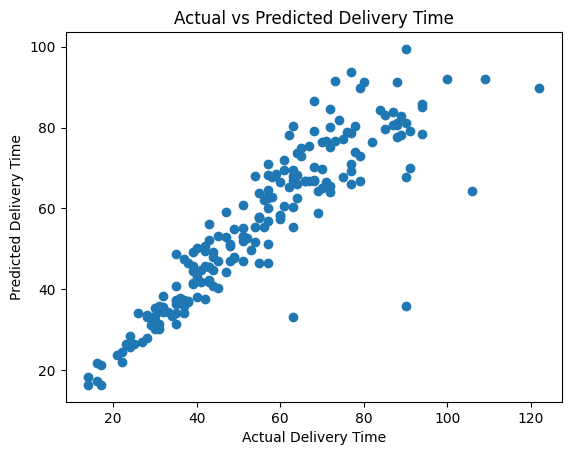

In [31]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Delivery Time")
plt.ylabel("Predicted Delivery Time")
plt.title("Actual vs Predicted Delivery Time")
plt.show()

### Ridge Regression
Train a Ridge regression model on the training data, predict delivery times for the test set, and evaluate its accuracy using MAE, MSE, and R².

In [32]:
ridge = Ridge()
ridge.fit(X_train,y_train)
pred = ridge.predict(X_test)
mean_absolute_error(y_test, pred)
mean_squared_error(y_test, pred)
r2_score(y_test, pred)

0.8183252656437564

### next

In [35]:
df = df_copy.copy()

In [36]:
df

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68
...,...,...,...,...,...,...,...,...,...
995,107,8.50,Clear,High,Evening,Car,13,3.0,54
996,271,16.28,Rainy,Low,Morning,Scooter,8,9.0,71
997,861,15.62,Snowy,High,Evening,Scooter,26,2.0,81
998,436,14.17,Clear,Low,Afternoon,Bike,8,0.0,55


In [37]:
X = df.drop(
    ['Order_ID', 'Delivery_Time_min'],
    axis=1
)

y = df['Delivery_Time_min']

### Identify numerical and categorical columns

In [38]:
categorical_cols = X.select_dtypes(
    include=['object']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=['number']
).columns.tolist()

print("Categorical:", categorical_cols)
print("Numerical:", numerical_cols)

Categorical: ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']
Numerical: ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']


### Create preprocessing pipeline

In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numerical_cols),
    ('cat', categorical_transformer, categorical_cols)
])

### Split data

In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(800, 7)
(200, 7)


### Create new features

In [41]:
X_fe = X_train.copy()
X_test_fe = X_test.copy()

X_fe['Total_Preparation_Distance'] = (
    X_fe['Distance_km'] * X_fe['Preparation_Time_min']
)

X_test_fe['Total_Preparation_Distance'] = (
    X_test_fe['Distance_km'] * X_test_fe['Preparation_Time_min']
)

X_fe['Distance_per_Experience'] = (
    X_fe['Distance_km'] / (X_fe['Courier_Experience_yrs'] + 1)
)

X_test_fe['Distance_per_Experience'] = (
    X_test_fe['Distance_km'] / (X_test_fe['Courier_Experience_yrs'] + 1)
)

In [42]:
X_fe.head()

,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Total_Preparation_Distance,Distance_per_Experience
29,18.05,Clear,Medium,Evening,Scooter,10,7.0,180.50,2.256250
535,2.14,Clear,High,Evening,Bike,18,3.0,38.52,0.535000
695,3.23,Clear,High,Afternoon,Bike,17,9.0,54.91,0.323000
557,7.51,Rainy,Low,Evening,Car,27,6.0,202.77,1.072857
836,4.62,Rainy,Medium,Afternoon,Car,8,3.0,36.96,1.155000


### Compare feature shapes

In [43]:
print("Original Features:", X_train.shape)
print("New Features:", X_fe.shape)

Original Features: (800, 7)
New Features: (800, 9)


### Update numerical and categorical columns

In [44]:
numerical_cols = X_fe.select_dtypes(
    include=['number']
).columns.tolist()

categorical_cols = X_fe.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical:", numerical_cols)
print("Categorical:", categorical_cols)

Numerical: ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs', 'Total_Preparation_Distance', 'Distance_per_Experience']
Categorical: ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']


In [45]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

In [46]:
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(random_state=42))
])

In [47]:
param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 5, 10, 15],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2]
}

In [48]:
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_fe, y_train)

Fitting 5 folds for each of 32 candidates, totalling 160 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__max_depth': [None, 5, ...], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100, 200]}"
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [49]:
print("Best Parameters:", grid_search.best_params_)

print("Best CV RMSE:", -grid_search.best_score_)

Best Parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 100}
Best CV RMSE: 11.969965438392531


### Test performance

In [50]:
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test_fe)

In [51]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 6.722507072664866
RMSE: 9.609810030715181
R2 Score: 0.793969453028939


### Calculate residuals

In [52]:
residuals = y_test - y_pred

residuals.head()

521   -2.998615
737    1.301425
740   -0.785916
660   -3.364326
411    6.650962
Name: Delivery_Time_min, dtype: float64

### Residual distribution

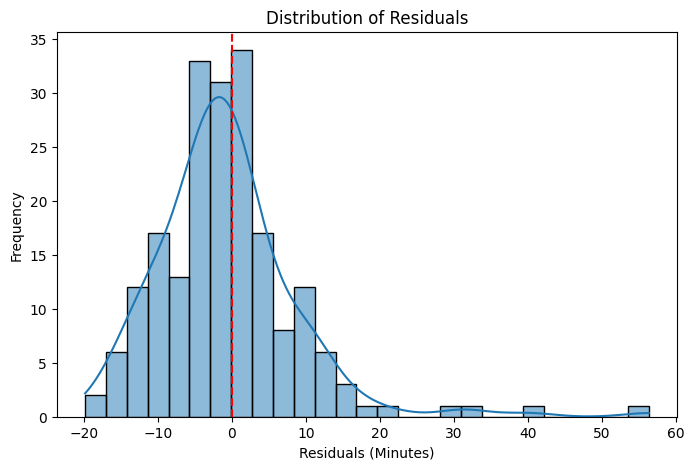

In [53]:
plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.axvline(0, color='red', linestyle='--')

plt.title("Distribution of Residuals")
plt.xlabel("Residuals (Minutes)")
plt.ylabel("Frequency")

plt.show()

### Residuals vs Predicted Values

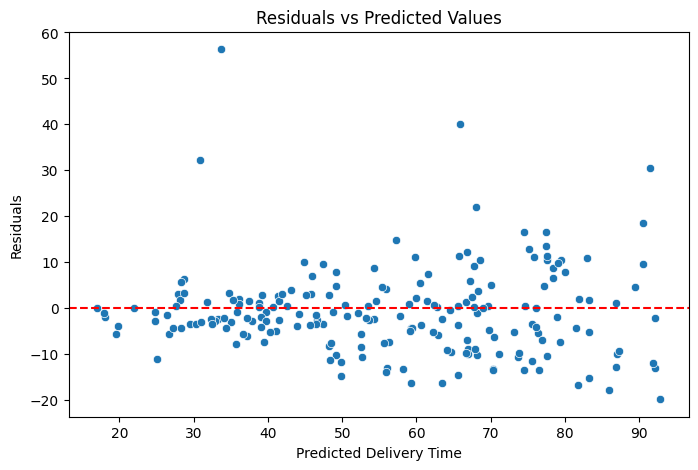

In [54]:
plt.figure(figsize=(8, 5))

sns.scatterplot(x=y_pred, y=residuals)

plt.axhline(0, color='red', linestyle='--')

plt.title("Residuals vs Predicted Values")
plt.xlabel("Predicted Delivery Time")
plt.ylabel("Residuals")

plt.show()

### Actual vs Predicted

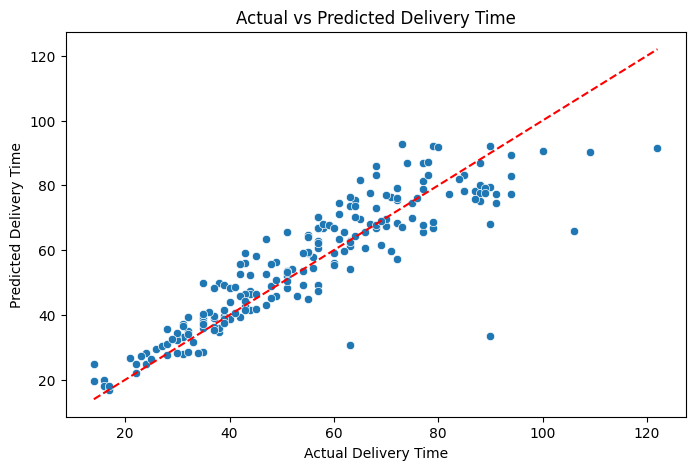

In [55]:
plt.figure(figsize=(8, 5))

sns.scatterplot(x=y_test, y=y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)

plt.title("Actual vs Predicted Delivery Time")
plt.xlabel("Actual Delivery Time")
plt.ylabel("Predicted Delivery Time")

plt.show()

### Check prediction errors

In [56]:
error_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred,
    'Residual': residuals
})

error_df['Absolute_Error'] = error_df['Residual'].abs()

error_df.sort_values(
    by='Absolute_Error',
    ascending=False
).head(10)

,Actual,Predicted,Residual,Absolute_Error
859,90,33.641760,56.358240,56.358240
570,106,65.911854,40.088146,40.088146
318,63,30.838170,32.161830,32.161830
924,122,91.442232,30.557768,30.557768
260,90,67.968817,22.031183,22.031183
866,73,92.830655,-19.830655,19.830655
595,109,90.431454,18.568546,18.568546
86,68,85.919511,-17.919511,17.919511
120,65,81.686333,-16.686333,16.686333
101,94,77.454079,16.545921,16.545921


### Single prediction

In [57]:
new_order = pd.DataFrame({
    'Distance_km': [10.5],
    'Weather': ['Clear'],
    'Traffic_Level': ['Medium'],
    'Time_of_Day': ['Evening'],
    'Vehicle_Type': ['Bike'],
    'Preparation_Time_min': [15],
    'Courier_Experience_yrs': [3]
})

prediction = best_model.predict(new_order)

print(f"Estimated Delivery Time: {prediction[0]:.2f} minutes")

Estimated Delivery Time: 59.06 minutes


### Multiple predictions

In [58]:
new_orders = pd.DataFrame({
    'Distance_km': [5, 10, 15, 20],
    'Weather': ['Clear', 'Rainy', 'Foggy', 'Clear'],
    'Traffic_Level': ['Low', 'Medium', 'High', 'High'],
    'Time_of_Day': ['Morning', 'Evening', 'Night', 'Afternoon'],
    'Vehicle_Type': ['Bike', 'Scooter', 'Car', 'Bike'],
    'Preparation_Time_min': [10, 15, 20, 25],
    'Courier_Experience_yrs': [5, 3, 2, 7]
})

predictions = best_model.predict(new_orders)

result = new_orders.copy()
result['Predicted_Delivery_Time_min'] = predictions.round(2)

result

,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Predicted_Delivery_Time_min
0,5,Clear,Low,Morning,Bike,10,5,30.22
1,10,Rainy,Medium,Evening,Scooter,15,3,59.40
2,15,Foggy,High,Night,Car,20,2,84.33
3,20,Clear,High,Afternoon,Bike,25,7,95.82


### Save your trained model

In [59]:
import pickle

with open("food_delivery_model.pkl", "wb") as file:
    pickle.dump(best_model, file)

print("Model saved successfully!")

Model saved successfully!


In [60]:
import os

project_path = r"E:\Food_Delivery_Prediction"

os.makedirs(project_path, exist_ok=True)

print("Project folder created:", project_path)

Project folder created: E:\Food_Delivery_Prediction


In [61]:
import shutil

shutil.copy(
    "food_delivery_model.pkl",
    os.path.join(project_path, "food_delivery_model.pkl")
)

print("Model copied successfully!")

Model copied successfully!


In [62]:
os.listdir(project_path)

['food_delivery_model.pkl']

In [63]:
requirements = """streamlit
pandas
numpy
scikit-learn
"""

with open(os.path.join(project_path, "requirements.txt"), "w") as file:
    file.write(requirements)

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [64]:
os.listdir(project_path)

['food_delivery_model.pkl', 'requirements.txt']

In [65]:
app_code = '''
import streamlit as st
import pandas as pd
import pickle

with open("food_delivery_model.pkl", "rb") as file:
    model = pickle.load(file)

st.set_page_config(
    page_title="Food Delivery Prediction",
    page_icon="🍔"
)

st.title("🍔 Food Delivery Time Prediction")
st.write("Predict estimated food delivery time using Machine Learning.")

st.divider()

st.subheader("Enter Delivery Details")

distance = st.number_input("Distance (km)", min_value=0.1, value=10.0)

weather = st.selectbox(
    "Weather", ["Clear", "Rainy", "Foggy", "Windy", "Snowy"]
)

traffic = st.selectbox(
    "Traffic Level", ["Low", "Medium", "High"]
)

time_of_day = st.selectbox(
    "Time of Day", ["Morning", "Afternoon", "Evening", "Night"]
)

vehicle = st.selectbox(
    "Vehicle Type", ["Bike", "Scooter", "Car"]
)

preparation = st.number_input(
    "Preparation Time (minutes)", min_value=1, value=15
)

experience = st.number_input(
    "Courier Experience (years)", min_value=0, value=3
)

if st.button("Predict Delivery Time"):

    input_data = pd.DataFrame({
        "Distance_km": [distance],
        "Weather": [weather],
        "Traffic_Level": [traffic],
        "Time_of_Day": [time_of_day],
        "Vehicle_Type": [vehicle],
        "Preparation_Time_min": [preparation],
        "Courier_Experience_yrs": [experience]
    })

    prediction = model.predict(input_data)[0]

    st.success(
        f"Estimated Delivery Time: {prediction:.2f} minutes"
    )

    st.caption("This is an estimated delivery time, not a guarantee.")
'''

with open(os.path.join(project_path, "app.py"), "w", encoding="utf-8") as file:
    file.write(app_code)

print("app.py created successfully!")

app.py created successfully!


In [66]:
os.listdir(project_path)

['app.py', 'food_delivery_model.pkl', 'requirements.txt']